The code is inspired by : https://github.com/google-deepmind/deepmind-research/blob/master/enformer/enformer-usage.ipynb


In [1]:
import tensorflow as tf
# Make sure the GPU is enabled
assert tf.config.list_physical_devices('GPU'), 'Start the colab kernel with GPU: Runtime -> Change runtime type -> GPU'

In [2]:
!pip install kipoiseq==0.5.2 --quiet > /dev/null
# You can ignore the pyYAML error

In [3]:
import tensorflow_hub as hub
import joblib
import gzip
import kipoiseq
from kipoiseq import Interval
import pyfaidx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [4]:
# Install required genomics libraries
!pip install kipoiseq==0.5.2 pyfaidx cyvcf2 --quiet > /dev/null
import kipoiseq
from kipoiseq import Interval
import pyfaidx

import tensorflow as tf
import shutil

# Verify GPU
assert tf.config.list_physical_devices('GPU'), 'Start the colab kernel with GPU: Runtime -> Change runtime type -> GPU'

In [5]:
from google.colab import drive
drive.mount('/content/drive')

!ls -lh /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind/
!ls -lh /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind/gwas.amgen

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 4.2G
-rw------- 1 root root 178M Feb  2  2026 clinvar.vcf.gz
drwx------ 2 root root 4.0K Feb  2  2026 data
-rw------- 1 root root  11M Mar 25  2021 enformer.finetuned.SAD.robustscaler-PCA500-robustscaler.transform.pkl
-rw------- 1 root root 893M Feb  2  2026 enformer_model.tar.gz
-rw------- 1 root root  11M Feb  2  2026 enformer.transform.pkl
-rw------- 1 root root 3.1G Feb  2  2026 genome.fa
-rw------- 1 root root  19K Feb  2  2026 genome.fa.fai
drwx------ 4 root root 4.0K Sep 26 22:21 gwas.amgen
drwx------ 3 root root 4.0K Feb  2  2026 model
drwx------ 2 root root 4.0K Mar  5  2026 results
-rw------- 1 root root 783K Feb  2  2026 targets_human.txt
total 6.7M
-rw------- 1 root root 1.6M Mar  4  2026 41467_2025_64070_MOESM4_ESM.2a_NHCFV.snp.txt
-rw------- 1 root root 2.2M Mar  4  2026 41467_2025_64070_MOESM4_ESM.2b_HCM.snp.txt
-rw------- 1 root root  16

In [6]:
BASE_DIR = '/content/drive/MyDrive/Enformer_tutorial_Google_DeepMind/'

# Path to the downloaded transform pickle file
transform_path = f'{BASE_DIR}/enformer.finetuned.SAD.robustscaler-PCA500-robustscaler.transform.pkl'
# (Note: You also have 'enformer.transform.pkl' in your folder, so either works depending on which you want to use)

# Path to the extracted model directory
model_path = f'{BASE_DIR}/model/1'

# Paths to your genomic data files
fasta_file = f'{BASE_DIR}/genome.fa'
vcf_path = f'{BASE_DIR}/gwas.amgen/gwas.41467_2025_64070_MOESM4_ESM.2b_HCM.snp.txt.POS.ensembl_snv2.dbsnp138.broad.vcf.gz'

In [7]:
from cyvcf2 import VCF

vcf = VCF(vcf_path)
print("First 5 variants:")
for i, var in enumerate(vcf):
    # var.ALT is a list like ['G'] or ['A','T']
    print(var.CHROM, var.POS, var.ID, var.REF, var.ALT)
    if i == 4:
        break

First 5 variants:
1 3410232 rs6670123 C ['G']
1 11797979 rs17037388 A ['G']
1 11805747 rs13306561 A ['G']
1 24705677 rs66530629 G ['A']
1 26864920 rs1883660 A ['T']


In [8]:
import kagglehub

path = '/content/drive/MyDrive/Enformer_tutorial_Google_DeepMind/model'
print("Path to model files:", path)

Path to model files: /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind/model


In [9]:
with tf.io.gfile.GFile(transform_path, "rb") as f:
    transform = joblib.load(f)

print("Transform file loaded successfully!")

Transform file loaded successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid

In [10]:
# Read targets from the local /content directory

# Path to the extracted model directory
targets_txt = f'{BASE_DIR}/targets_human.txt'

df_targets = pd.read_csv(targets_txt, sep='\t')
df_targets.head(3)

,index,genome,identifier,file,clip,scale,sum_stat,description
0,0,0,ENCFF833POA,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:cerebellum male adult (27 years) and mal...
1,1,0,ENCFF110QGM,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:frontal cortex male adult (27 years) and...
2,2,0,ENCFF880MKD,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:chorion


### **Classes:**  
### **Enformer**
### **EnformerScoreVariantsNormalized**
### **EnformerScoreVariantsPCANormalized**

In [11]:
SEQUENCE_LENGTH = 393216

class Enformer:

  def __init__(self, tfhub_url):
    self._model = hub.load(tfhub_url).model

  def predict_on_batch(self, inputs):
    predictions = self._model.predict_on_batch(inputs)
    return {k: v.numpy() for k, v in predictions.items()}

  @tf.function
  def contribution_input_grad(self, input_sequence,
                              target_mask, output_head='human'):
    input_sequence = input_sequence[tf.newaxis]

    target_mask_mass = tf.reduce_sum(target_mask)
    with tf.GradientTape() as tape:
      tape.watch(input_sequence)
      prediction = tf.reduce_sum(
          target_mask[tf.newaxis] *
          self._model.predict_on_batch(input_sequence)[output_head]) / target_mask_mass

    input_grad = tape.gradient(prediction, input_sequence) * input_sequence
    input_grad = tf.squeeze(input_grad, axis=0)
    return tf.reduce_sum(input_grad, axis=-1)


class EnformerScoreVariantsRaw:

  def __init__(self, tfhub_url, organism='human'):
    self._model = Enformer(tfhub_url)
    self._organism = organism

  def predict_on_batch(self, inputs):
    ref_prediction = self._model.predict_on_batch(inputs['ref'])[self._organism]
    alt_prediction = self._model.predict_on_batch(inputs['alt'])[self._organism]

    return alt_prediction.mean(axis=1) - ref_prediction.mean(axis=1)


class EnformerScoreVariantsNormalized:

  def __init__(self, tfhub_url, transform_pkl_path,
               organism='human'):
    assert organism == 'human', 'Transforms only compatible with organism=human'
    self._model = EnformerScoreVariantsRaw(tfhub_url, organism)
    with tf.io.gfile.GFile(transform_pkl_path, 'rb') as f:
      transform_pipeline = joblib.load(f)
    self._transform = transform_pipeline.steps[0][1]  # StandardScaler.

  def predict_on_batch(self, inputs):
    scores = self._model.predict_on_batch(inputs)
    return self._transform.transform(scores)


class EnformerScoreVariantsPCANormalized:

  def __init__(self, tfhub_url, transform_pkl_path,
               organism='human', num_top_features=500):
    self._model = EnformerScoreVariantsRaw(tfhub_url, organism)
    with tf.io.gfile.GFile(transform_pkl_path, 'rb') as f:
      self._transform = joblib.load(f)
    self._num_top_features = num_top_features

  def predict_on_batch(self, inputs):
    scores = self._model.predict_on_batch(inputs)
    return self._transform.transform(scores)[:, :self._num_top_features]

In [12]:
import pandas as pd

# df_targets = pd.read_csv(
#    'https://raw.githubusercontent.com/calico/basenji/master/manuscripts/cross2020/targets_human.txt',
#    sep='\t'
# )

# Count by major categories
cage_tracks = df_targets[df_targets['description'].str.contains('CAGE', na=False)]
dnase_tracks = df_targets[df_targets['description'].str.contains('DNASE', na=False)]
chip_tracks = df_targets[df_targets['description'].str.contains('CHIP', na=False)]

print(f"CAGE tracks: {len(cage_tracks)}")    # ~4,900
print(f"DNase tracks: {len(dnase_tracks)}")  # ~600
print(f"ChIP tracks: {len(chip_tracks)}")    # ~2,200

# Extract unique cell types (very rough estimate)
def simple_cell_extract(desc):
    # Just split and take middle parts
    parts = desc.split(':')
    if len(parts) > 1:
        return parts[-1].split(' ')[0:3]  # First 3 words
    return desc

# This is approximate!
all_cells = set()
for desc in df_targets['description']:
    cell = simple_cell_extract(desc)
    all_cells.add(' '.join(cell))

print(f"\nApproximate unique contexts: {len(all_cells)}")


CAGE tracks: 638
DNase tracks: 674
ChIP tracks: 3991

Approximate unique contexts: 1187


In [13]:
# Let's find all tracks for a specific organ
import pandas as pd

# Find all keratinocyte tracks
brain_tracks = df_targets[
    df_targets['description'].str.contains('brain', case=False, na=False)
]

print(f"Total brain tracks: {len(brain_tracks)}")
print("\nExamples:")
for idx, row in brain_tracks.head(10).iterrows():
    print(f"  [{idx}] {row['description']}")


Total brain tracks: 36

Examples:
  [80] DNASE:brain microvascular endothelial cell
  [81] DNASE:brain pericyte
  [82] DNASE:smooth muscle cell of the brain vasculature female
  [179] DNASE:brain female embryo (85 days)
  [216] DNASE:brain embryo (112 days)
  [240] DNASE:brain female embryo (96 days)
  [261] DNASE:brain female embryo (142 days)
  [319] DNASE:brain female embryo (117 days)
  [338] DNASE:brain female embryo (109 days)
  [370] DNASE:brain male embryo (105 days)


In [14]:
# Let's find all tracks for a specific cell type
import pandas as pd

# Find all neuron tracks
neuron_tracks = df_targets[
    df_targets['description'].str.contains('neuron', case=False, na=False)
]

print(f"Total neuron tracks: {len(neuron_tracks)}")
print("\nExamples:")
for idx, row in neuron_tracks.head(10).iterrows():
    print(f"  [{idx}] {row['description']}")


Total neuron tracks: 27

Examples:
  [485] DNASE:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [1444] CHIP:H3K9me3:neuron originated from H9
  [1644] CHIP:CTCF:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [1998] CHIP:H3K9me2:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [2223] CHIP:H3K9me3:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [2375] CHIP:H3K4me1:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [2409] CHIP:H3K4me3:neuron originated from H9
  [2592] CHIP:H3K36me3:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [2721] CHIP:ZEB1:bipolar neuron originated from GM23338 treated with 0.5 ug/mL doxycycline hyclate for 4 days
  [2896] CHIP:H3K27me3:bipolar neuron originated from GM23338 treated with 0.

In [15]:
import pandas as pd


# Extract ChIP-seq tracks
chip_tracks = df_targets[df_targets['description'].str.contains('CHIP:', na=False)]

# Extract histone mark types
import re
histone_marks = set()
for desc in chip_tracks['description']:
    # Pattern: CHIP:H3K27ac:cell_type or CHIP:H3K4me3:cell_type
    match = re.search(r'H\d[A-Z]\w+', desc)
    if match:
        histone_marks.add(match.group())

print(f"Unique histone marks: {len(histone_marks)}")
for mark in sorted(histone_marks):
    count = chip_tracks['description'].str.contains(mark, na=False).sum()
    print(f"  {mark}: {count} tracks")

Unique histone marks: 36
  H2AFZ: 45 tracks
  H2AK5ac: 7 tracks
  H2AK9ac: 1 tracks
  H2BK120ac: 7 tracks
  H2BK12ac: 7 tracks
  H2BK15ac: 6 tracks
  H2BK20ac: 3 tracks
  H2BK5ac: 7 tracks
  H3F3A: 16 tracks
  H3K14ac: 7 tracks
  H3K18ac: 7 tracks
  H3K23ac: 8 tracks
  H3K23me2: 2 tracks
  H3K27Ac: 1 tracks
  H3K27ac: 228 tracks
  H3K27me3: 260 tracks
  H3K36me3: 269 tracks
  H3K4ac: 8 tracks
  H3K4me1: 260 tracks
  H3K4me1_Rabbit_PassedQC: 1 tracks
  H3K4me2: 41 tracks
  H3K4me3: 339 tracks
  H3K4me3_Rabbit_PassedQC: 1 tracks
  H3K56ac: 3 tracks
  H3K79me1: 8 tracks
  H3K79me2: 36 tracks
  H3K9ac: 98 tracks
  H3K9me1: 2 tracks
  H3K9me2: 16 tracks
  H3K9me3: 252 tracks
  H3T11ph: 1 tracks
  H4K12ac: 1 tracks
  H4K20me1: 36 tracks
  H4K5ac: 4 tracks
  H4K8ac: 8 tracks
  H4K91ac: 6 tracks


### **Variant centered sequences. Plot tracks**

In [16]:
import kipoiseq
from kipoiseq import Interval
import pyfaidx
import numpy as np

class FastaStringExtractor:

    def __init__(self, fasta_file):
        self.fasta = pyfaidx.Fasta(fasta_file)
        self._chromosome_sizes = {k: len(v) for k, v in self.fasta.items()}

    def extract(self, interval: Interval, **kwargs) -> str:
        # Truncate interval if it extends beyond the chromosome lengths.
        chromosome_length = self._chromosome_sizes[interval.chrom]
        trimmed_interval = Interval(interval.chrom,
                                    max(interval.start, 0),
                                    min(interval.end, chromosome_length),
                                    )
        # pyfaidx wants a 1-based interval
        sequence = str(self.fasta.get_seq(trimmed_interval.chrom,
                                          trimmed_interval.start + 1,
                                          trimmed_interval.stop).seq).upper()
        # Fill truncated values with N's.
        pad_upstream = 'N' * max(-interval.start, 0)
        pad_downstream = 'N' * max(interval.end - chromosome_length, 0)
        return pad_upstream + sequence + pad_downstream

    def close(self):
        return self.fasta.close()


def variant_generator(vcf_file, gzipped=False):
  """Yields a kipoiseq.dataclasses.Variant for each row in VCF file."""
  def _open(file):
    return gzip.open(vcf_file, 'rt') if gzipped else open(vcf_file)

  with _open(vcf_file) as f:
    for line in f:
      if line.startswith('#'):
        continue
      chrom, pos, id, ref, alt_list = line.split('\t')[:5]
      # Split ALT alleles and return individual variants as output.
      for alt in alt_list.split(','):
        yield kipoiseq.dataclasses.Variant(chrom=chrom, pos=pos,
                                           ref=ref, alt=alt, id=id)


def one_hot_encode(sequence):
  return kipoiseq.transforms.functional.one_hot_dna(sequence).astype(np.float32)


def variant_centered_sequences(vcf_file, sequence_length, gzipped=False,
                               chr_prefix=''):
  seq_extractor = kipoiseq.extractors.VariantSeqExtractor(
    reference_sequence=FastaStringExtractor(fasta_file))

  for variant in variant_generator(vcf_file, gzipped=gzipped):
    interval = Interval(chr_prefix + variant.chrom,
                        variant.pos, variant.pos)
    interval = interval.resize(sequence_length)
    center = interval.center() - interval.start

    reference = seq_extractor.extract(interval, [], anchor=center)
    alternate = seq_extractor.extract(interval, [variant], anchor=center)

    yield {'inputs': {'ref': one_hot_encode(reference),
                      'alt': one_hot_encode(alternate)},
           'metadata': {'chrom': chr_prefix + variant.chrom,
                        'pos': variant.pos,
                        'id': variant.id,
                        'ref': variant.ref,
                        'alt': variant.alt}}

In [17]:
def plot_tracks(tracks, interval, height=1.5):
  fig, axes = plt.subplots(len(tracks), 1, figsize=(20, height * len(tracks)), sharex=True)
  for ax, (title, y) in zip(axes, tracks.items()):
    ax.fill_between(np.linspace(interval.start, interval.end, num=len(y)), y)
    ax.set_title(title)
    sns.despine(top=True, right=True, bottom=True)
  ax.set_xlabel(str(interval))
  plt.tight_layout()

## **Variant scoring example**

In [18]:
model = Enformer(model_path)

fasta_extractor = FastaStringExtractor(fasta_file)

In [19]:
# @title Score the variant
variant = kipoiseq.Variant('chr21', 29164391, 'G', 'T', id='rs2832230')  # @param

# Center the interval at the variant
interval = kipoiseq.Interval(variant.chrom, variant.start, variant.start).resize(SEQUENCE_LENGTH)
seq_extractor = kipoiseq.extractors.VariantSeqExtractor(reference_sequence=fasta_extractor)
center = interval.center() - interval.start

reference = seq_extractor.extract(interval, [], anchor=center)
alternate = seq_extractor.extract(interval, [variant], anchor=center)

# Make predictions for the refernece and alternate allele
reference_prediction = model.predict_on_batch(one_hot_encode(reference)[np.newaxis])['human'][0]
alternate_prediction = model.predict_on_batch(one_hot_encode(alternate)[np.newaxis])['human'][0]

In [20]:
# We need to look up the track indices from df_targets by matching the description string,
# then plug those indices into your tracks = {...} dict.

# df_targets must have columns like: ['index','genome','identifier','file','clip','scale','sum_stat','description']

cand = df_targets[
    df_targets['description'].str.contains('CAGE', case=False, na=False) &
    df_targets['description'].str.contains('brain', case=False, na=False)
]

cand[['index','description']].head(20)


,index,description
4680,4680,"CAGE:brain, adult, pool1"
4768,4768,"CAGE:Smooth Muscle Cells - Brain Vascular,"
4980,4980,"CAGE:brain, adult,"
4981,4981,"CAGE:brain, fetal, pool1"


In [21]:
cand = df_targets[
    df_targets['description'].str.contains('CAGE', case=False, na=False) &
    df_targets['description'].str.contains('neuron', case=False, na=False)
]

cand[['index','description']].head(20)


,index,description
5112,5112,"CAGE:Neurons,"


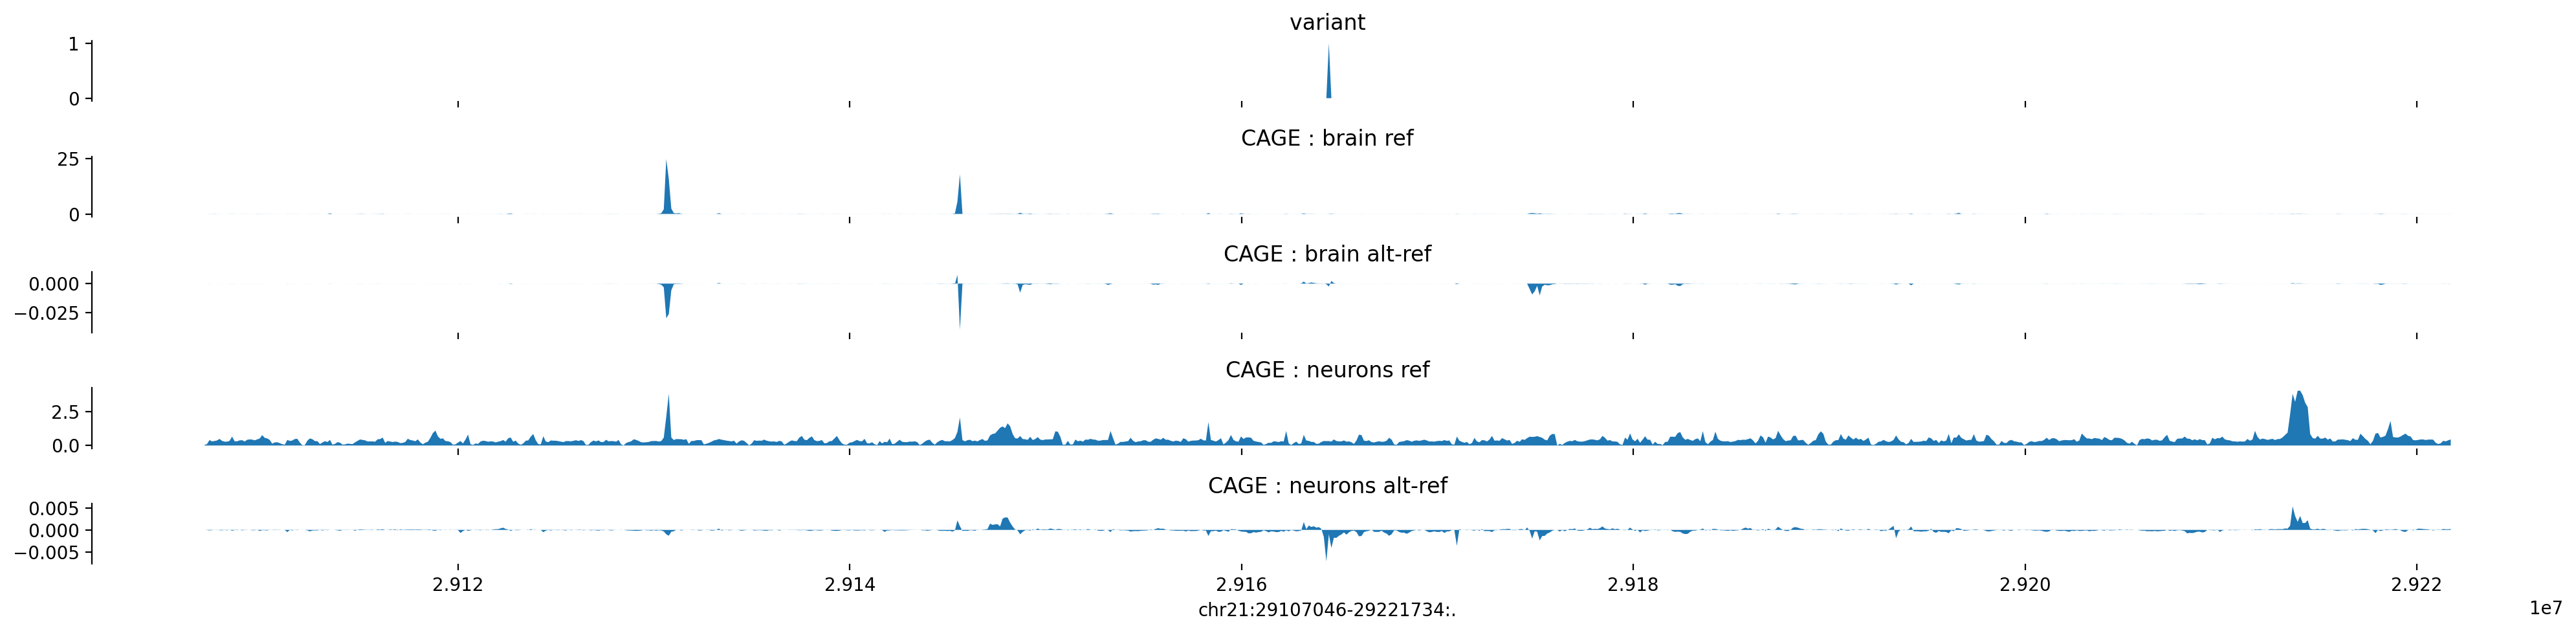

In [22]:
# @title Visualize some tracks
variant_track = np.zeros_like(reference_prediction[:, 0], dtype=bool)
variant_track[variant_track.shape[0] // 2] = True
tracks = {'variant': variant_track,
          'CAGE : brain ref': reference_prediction[:, 4780],
          'CAGE : brain alt-ref': alternate_prediction[:, 4780] - reference_prediction[:, 4780],
          'CAGE : neurons ref': reference_prediction[:, 5112],
          'CAGE : neurons alt-ref': alternate_prediction[:, 5112] - reference_prediction[:, 5112],
          }

plot_tracks(tracks, interval.resize(reference_prediction.shape[0] * 128), height=1)

# ChIP:H3K27ac / neutrophil — alt − ref
# Difference track for H3K27ac: alt − ref

# The deep negative valley centered on the variant means:
# The alternate allele strongly reduces predicted H3K27ac.

# In other words, the variant weakens enhancer/promoter activity.

## **Score variants in a VCF file**

## **Score variants in a VCF file : EnformerScoreVariantsPCANormalized**
##### enformer_score_variants = EnformerScoreVariantsPCANormalized(
##### model_path,
##### transform_path,
##### num_top_features=20)

In [23]:
# INITIALIZE THE PCA SCORER
# (This gives you the 20 PCs instead of the 5,313 raw tracks)

enformer_score_variants_pca = EnformerScoreVariantsPCANormalized(model_path, transform_path, num_top_features=20)

# RUN THE VARIANT SCORING
it = variant_centered_sequences(vcf_path,
                                sequence_length=SEQUENCE_LENGTH,
                                gzipped=True,
                                chr_prefix='chr')

example_list = []
for i, example in enumerate(it):
  if i >= 5:
    break

  # Predict using the PCA scorer
  variant_scores = enformer_score_variants_pca.predict_on_batch(
      {k: v[tf.newaxis] for k,v in example['inputs'].items()})[0]

  # Label the columns as PC0, PC1, etc.
  variant_scores = {f'PC{i}': score for i, score in enumerate(variant_scores)}

  example_list.append({**example['metadata'],
                       **variant_scores})

# Create the DataFrame with PC columns
df_pca = pd.DataFrame(example_list)
df_pca



/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid

,chrom,pos,id,ref,alt,PC0,PC1,PC2,PC3,PC4,...,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19
0,chr1,3410232,rs6670123,C,G,-4.515934,4.529421,-2.973453,6.781376,5.982105,...,-4.723419,2.277445,-8.432272,5.338778,0.747635,-2.498500,-3.812069,1.371198,2.873829,-6.300097
1,chr1,11797979,rs17037388,A,G,-72.682320,111.498871,-41.025257,19.142115,72.413528,...,122.748138,-9.879939,19.831675,14.196251,26.181717,131.531357,-123.566254,-77.536087,-76.134338,58.244946
2,chr1,11805747,rs13306561,A,G,-32.065952,24.210320,2.124517,19.319540,-15.858222,...,-24.597305,7.725200,2.153812,0.258301,-0.407560,-17.841642,22.312197,17.980822,19.483356,-39.544369
3,chr1,24705677,rs66530629,G,A,-29.988970,75.788795,-39.701622,85.875786,8.336361,...,27.580591,4.246973,21.958704,-53.102955,27.775650,-24.131689,41.396484,-10.509380,-9.520148,-5.722460
4,chr1,26864920,rs1883660,A,T,16.247469,4.297072,14.571508,1.858903,46.497398,...,-34.050205,-27.451559,17.163115,-7.385268,-13.897474,15.374649,-3.256710,34.546406,-7.767971,31.606205


In [24]:
output_path = f'{BASE_DIR}/gwas.amgen/NHCFV.enformer_scores_PCA20.tsv'
df_pca.to_csv(output_path, sep='\t', index=False)
print(f'Saved {len(df_pca)} variants → {output_path}')

Saved 5 variants → /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/NHCFV.enformer_scores_PCA20.tsv


## **Score variants in a VCF file : EnformerScoreVariantsNormalized : allvariants**

##### enformer_score_variants_all = EnformerScoreVariantsNormalized(
##### model_path,
##### transform_path)

In [25]:
# INITIALIZE THE SCORER FIRST :
# Connects your local model and the transform pickle file

# Loads the model + the z-score normalizer (StandardScaler).
# Output will be 5,313 z-scores per variant — one per Enformer track (CAGE, DNase, ChIP...)

enformer_score_variants_all = EnformerScoreVariantsNormalized(model_path, transform_path)

# RUN THE VARIANT SCORING
# Score the first 5 variants All Scores)

# Creates the variant generator
# Scores each variant

it = variant_centered_sequences(vcf_path,
                                sequence_length=SEQUENCE_LENGTH,
                                gzipped=True,
                                chr_prefix='chr')

example_list = []
for i, example in enumerate(it):
  if i >= 5:
    break

  # Predict on the batch using the scorer we just defined
  variant_scores = enformer_score_variants_all.predict_on_batch(
      {k: v[tf.newaxis] for k,v in example['inputs'].items()})[0]

  variant_scores = {f'{i}_{name[:20]}': score for i, (name, score) in enumerate(zip(df_targets.description, variant_scores))}

  example_list.append({**example['metadata'],
                       **variant_scores})

  if i % 2 == 0:
    print(f'Done {i}')

df = pd.DataFrame(example_list)
df

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 0.23.2 when using version 1.6.1. This might lead to breaking code or invalid

Done 0
Done 2
Done 4


,chrom,pos,id,ref,alt,0_DNASE:cerebellum mal,1_DNASE:frontal cortex,2_DNASE:chorion,3_DNASE:Ishikawa treat,4_DNASE:GM03348,...,"5303_CAGE:thalamus, adult","5304_CAGE:putamen, adult,",5305_CAGE:parietal cortex,5306_CAGE:medial temporal,5307_CAGE:squamous cell l,5308_CAGE:epithelioid sar,5309_CAGE:squamous cell l,5310_CAGE:gastric cancer,5311_CAGE:carcinoid cell,5312_CAGE:lung adenocarci
0,chr1,3410232,rs6670123,C,G,-11.370432,-11.203447,14.438162,-5.976363,-11.623825,...,-1.265905,-2.193654,-2.219817,-2.843207,-3.226923,-7.335872,-0.948502,-6.617390,-3.364311,-1.587036
1,chr1,11797979,rs17037388,A,G,-5.596322,-21.329639,-19.790432,21.243084,-2.807821,...,41.848679,42.045078,34.260799,24.858013,-28.994341,21.890560,-12.932393,-13.383186,-25.285152,-4.123004
2,chr1,11805747,rs13306561,A,G,-5.451073,-1.152355,4.991023,-3.564867,-4.547742,...,-15.470111,-26.475147,-21.802412,-10.438047,-46.444881,-35.017960,-30.389614,-13.406905,0.864351,-8.673202
3,chr1,24705677,rs66530629,G,A,-9.579816,-10.136042,11.095270,-9.285522,-36.403454,...,-5.603980,1.636797,-0.465287,0.987401,-20.856375,-24.228853,-8.691240,-23.153370,-24.796318,-69.234779
4,chr1,26864920,rs1883660,A,T,13.549163,6.280086,4.624414,2.520011,-3.839648,...,-7.575530,-6.317173,-10.054835,-7.956751,43.524788,-75.591980,-40.193398,-10.236488,-3.585367,-6.103715


In [26]:
# Save to Google Drive
output_path_all = f'{BASE_DIR}/gwas.amgen/NHCFV.enformer_scores_all5313.tsv'
df.to_csv(output_path_all, sep='\t', index=False)
print(f'Saved {len(df)} variants x {len(df.columns)} tracks → {output_path_all}')

Saved 5 variants x 5318 tracks → /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/NHCFV.enformer_scores_all5313.tsv


Figure saved → /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/NHCFV.enformer_PCA_scatter.png


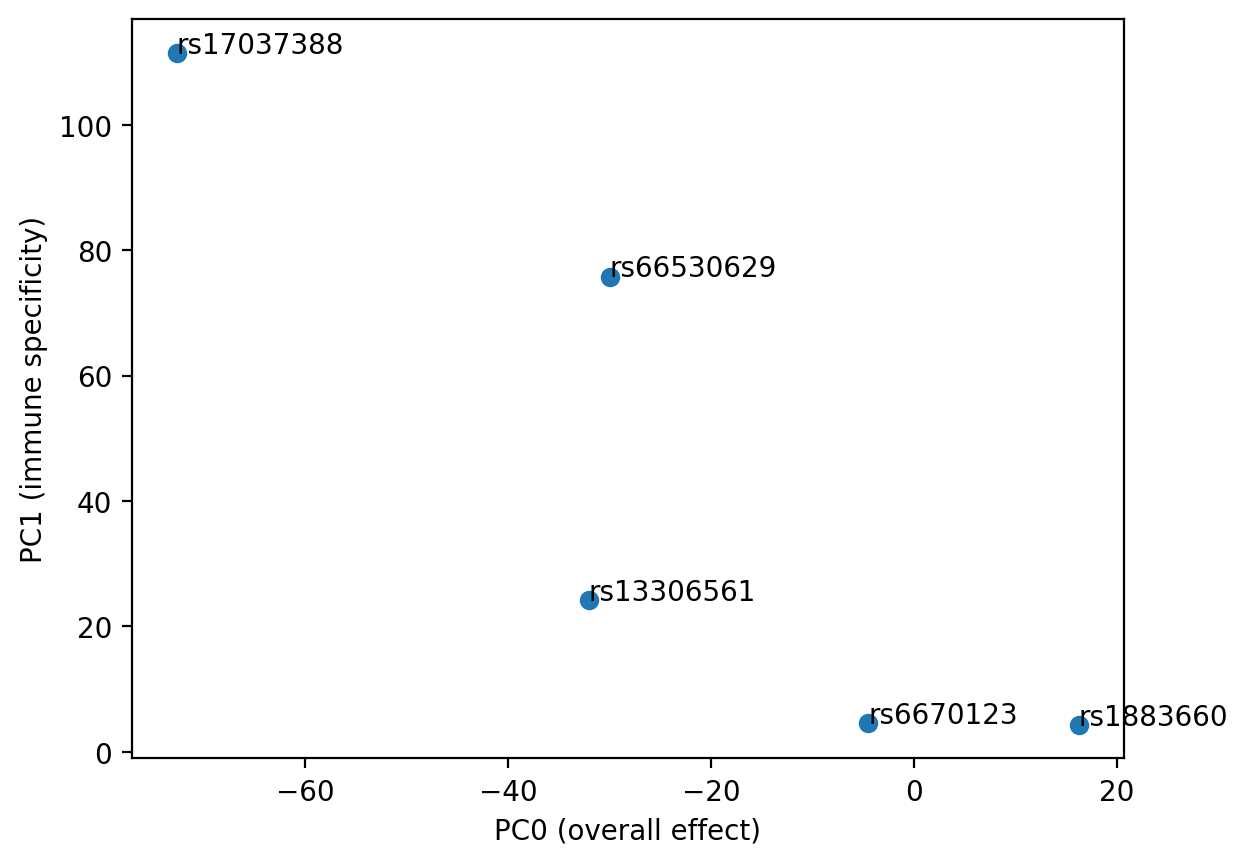

In [27]:
# PLOT THE DATA
# (Using df_pca so it doesn't conflict with your other dataframes)
import matplotlib.pyplot as plt

plt.scatter(df_pca['PC0'], df_pca['PC1'])
for idx, row in df_pca.iterrows():
    plt.annotate(row['id'], (row['PC0'], row['PC1']))
plt.xlabel('PC0 (overall effect)')
plt.ylabel('PC1 (immune specificity)')

# Save to Google Drive
fig_path = f'{BASE_DIR}/gwas.amgen/NHCFV.enformer_PCA_scatter.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f'Figure saved → {fig_path}')

plt.show()

In [28]:
# Select Enformer track columns, excluding variant metadata
score_cols = [
    col for col in df.columns
    if str(col).split("_", 1)[0].isdigit() and "_" in str(col)
]

assert score_cols, "No track columns found. Run the all-track scoring cell first."
print(f"Found {len(score_cols)} score columns")

Found 5313 score columns


In [29]:
print(score_cols)

['0_DNASE:cerebellum mal', '1_DNASE:frontal cortex', '2_DNASE:chorion', '3_DNASE:Ishikawa treat', '4_DNASE:GM03348', '5_DNASE:GM03348 geneti', '6_DNASE:AG08395', '7_DNASE:AG08396', '8_DNASE:AG20443', '9_DNASE:frontal cortex', '10_DNASE:H54', '11_DNASE:GM10248', '12_DNASE:GM12878', '13_DNASE:GM12891', '14_DNASE:GM12892', '15_DNASE:GM18507', '16_DNASE:GM19238', '17_DNASE:GM19239', '18_DNASE:GM19240', '19_DNASE:H1-hESC', '20_DNASE:H7-hESC', '21_DNASE:H9', '22_DNASE:heart male adu', '23_DNASE:HEK293T', '24_DNASE:HeLa-S3 treate', '25_DNASE:HeLa-S3', '26_DNASE:hepatocyte', '27_DNASE:HepG2', '28_DNASE:HTR-8/SVneo', '29_DNASE:endothelial ce', '30_DNASE:CWRU1 male', '31_DNASE:iPS-NIHi11 mal', '32_DNASE:iPS-NIHi7 fema', '33_DNASE:K562 treated w', '34_DNASE:K562 G2 phase', '35_DNASE:K562 G1 phase', '36_DNASE:LNCaP clone FG', '37_DNASE:LNCaP clone FG', '38_DNASE:MCF-7 originat', '39_DNASE:medulloblastom', '40_DNASE:epidermal mela', '41_DNASE:CD14-positive ', '42_DNASE:keratinocyte f', '43_DNASE:os

In [30]:
results = []
for idx, row in df.iterrows():
    scores = row[score_cols]
    top10 = scores.abs().sort_values(ascending=False).head(10)
    for rank, track in enumerate(top10.index, 1):
        results.append({
            'variant_id': row['id'],
            'chrom': row['chrom'],
            'pos': row['pos'],
            'ref': row['ref'],
            'alt': row['alt'],
            'rank': rank,
            'track': track,
            'score': scores[track],
            'abs_score': abs(scores[track]),
            'direction': 'INCREASE' if scores[track] > 0 else 'DECREASE'
        })

df_top = pd.DataFrame(results)

# Save to Drive
df_top.to_csv(f'{BASE_DIR}/gwas.amgen/NHCFV.enformer_top10_tissues_per_variant.tsv',
              sep='\t', index=False)
print(df_top)

    variant_id chrom       pos ref alt  rank                      track  \
0    rs6670123  chr1   3410232   C   G     1  4078_CHIP:H3K4me1:CD8-pos   
1    rs6670123  chr1   3410232   C   G     2  4411_CHIP:H3K4me1:natural   
2    rs6670123  chr1   3410232   C   G     3     1112_CHIP:CTCF:AG09319   
3    rs6670123  chr1   3410232   C   G     4     4086_CHIP:POLR2G:HepG2   
4    rs6670123  chr1   3410232   C   G     5     1114_CHIP:CTCF:AG10803   
5    rs6670123  chr1   3410232   C   G     6  1116_CHIP:CTCF:fibroblast   
6    rs6670123  chr1   3410232   C   G     7  4365_CHIP:POLR2AphosphoS5   
7    rs6670123  chr1   3410232   C   G     8  4949_CAGE:aorta, adult, p   
8    rs6670123  chr1   3410232   C   G     9  1219_CHIP:CTCF:foreskin f   
9    rs6670123  chr1   3410232   C   G    10          1123_CHIP:CTCF:BJ   
10  rs17037388  chr1  11797979   A   G     1  4974_CAGE:left ventricle,   
11  rs17037388  chr1  11797979   A   G     2  4684_CAGE:heart, adult, p   
12  rs17037388  chr1  117

In [31]:
# Filter df_top to keep only rows where track contains 'heart'
df_heart = df_top[df_top['track'].str.contains('heart', case=False)]

# Save to Drive
df_heart.to_csv(f'{BASE_DIR}/gwas.amgen/NHCFV.enformer_heart_tracks_per_variant.tsv',
                sep='\t', index=False)
print(f'Found {len(df_heart)} heart track entries')
print(df_heart)

Found 7 heart track entries
    variant_id chrom       pos ref alt  rank                      track  \
11  rs17037388  chr1  11797979   A   G     2  4684_CAGE:heart, adult, p   
12  rs17037388  chr1  11797979   A   G     3  4948_CAGE:heart, adult, d   
14  rs17037388  chr1  11797979   A   G     5  4714_CAGE:heart, fetal, p   
16  rs17037388  chr1  11797979   A   G     7  4947_CAGE:heart, adult, d   
20  rs13306561  chr1  11805747   A   G     1  4684_CAGE:heart, adult, p   
23  rs13306561  chr1  11805747   A   G     4  4714_CAGE:heart, fetal, p   
25  rs13306561  chr1  11805747   A   G     6  4948_CAGE:heart, adult, d   

          score    abs_score direction  
11 -2053.716797  2053.716797  DECREASE  
12 -1366.216431  1366.216431  DECREASE  
14 -1129.091553  1129.091553  DECREASE  
16  -847.534607   847.534607  DECREASE  
20   324.558014   324.558014  INCREASE  
23   237.762955   237.762955  INCREASE  
25   211.921127   211.921127  INCREASE  


In [32]:
import matplotlib.gridspec as gridspec

In [33]:
# ============================================================
# PLOT TOP HEART TRACKS PER VARIANT
# Using existing df_heart table directly
# One figure per variant, top 3 heart tracks
# ============================================================

def plot_variant_heart_tracks_from_df(df_heart, reference_predictions, alternate_predictions,
                                       base_dir, top_n=3):
    """
    Uses existing df_heart which already has:
    - variant_id, chrom, pos, ref, alt, rank, track, score, abs_score, direction
    Track column format: '4684_CAGE:heart, adult, p'
    """

    for variant_id, group in df_heart.groupby('variant_id'):

        # Get top N heart tracks by abs_score
        top_tracks = group.nsmallest(top_n, 'rank')  # rank 1,2,3 = top

        # Get variant metadata
        row0 = top_tracks.iloc[0]
        chrom = row0['chrom']
        pos   = row0['pos']
        ref   = row0['ref']
        alt   = row0['alt']

        # Get precomputed predictions for this variant
        ref_pred = reference_predictions[variant_id]   # shape (896, 5313)
        alt_pred = alternate_predictions[variant_id]   # shape (896, 5313)

        x = np.arange(ref_pred.shape[0])  # 896 bins

        for _, track_row in top_tracks.iterrows():

            # Extract track index from '4684_CAGE:heart, adult, p'
            track_idx = int(track_row['track'].split('_')[0])
            track_name = track_row['track'].split('_', 1)[1]  # 'CAGE:heart, adult, p'
            rank = track_row['rank']
            score = track_row['score']
            direction = track_row['direction']

            ref_track  = ref_pred[:, track_idx]
            alt_track  = alt_pred[:, track_idx]
            diff_track = alt_track - ref_track

            # ---- Figure with 4 panels ----
            fig = plt.figure(figsize=(22, 14))
            fig.suptitle(
                f"Variant: {variant_id}  |  {chrom}:{pos}  {ref}>{alt}\n"
                f"Rank #{rank} Heart Track [{track_idx}]: {track_name}  |  "
                f"Score: {score:.2f}  ({direction})",
                fontsize=13, fontweight='bold'
            )

            gs = gridspec.GridSpec(4, 1, hspace=0.6)

            # --- Panel 1: REF ---
            ax1 = fig.add_subplot(gs[0])
            ax1.fill_between(x, ref_track, alpha=0.7, color='steelblue')
            ax1.axvline(x=len(x)//2, color='red', linestyle='--', lw=1.2, label='Variant pos')
            ax1.set_title('REF prediction', fontsize=11)
            ax1.set_ylabel('Score')
            ax1.legend(fontsize=8)
            sns.despine(ax=ax1, top=True, right=True, bottom=True)

            # --- Panel 2: ALT ---
            ax2 = fig.add_subplot(gs[1])
            ax2.fill_between(x, alt_track, alpha=0.7, color='darkorange')
            ax2.axvline(x=len(x)//2, color='red', linestyle='--', lw=1.2)
            ax2.set_title('ALT prediction', fontsize=11)
            ax2.set_ylabel('Score')
            sns.despine(ax=ax2, top=True, right=True, bottom=True)

            # --- Panel 3: ALT - REF ---
            ax3 = fig.add_subplot(gs[2])
            ax3.fill_between(x, diff_track,
                             where=diff_track >= 0, alpha=0.7,
                             color='green', label='Increase')
            ax3.fill_between(x, diff_track,
                             where=diff_track < 0,  alpha=0.7,
                             color='red',   label='Decrease')
            ax3.axhline(0, color='black', lw=0.8)
            ax3.axvline(x=len(x)//2, color='red', linestyle='--', lw=1.2)
            ax3.set_title('ALT - REF (difference)', fontsize=11)
            ax3.set_ylabel('Delta Score')
            ax3.legend(fontsize=8)
            sns.despine(ax=ax3, top=True, right=True, bottom=True)

            # --- Panel 4: Heatmap ---
            ax4 = fig.add_subplot(gs[3])
            heatmap_data = np.vstack([ref_track, alt_track, diff_track])
            vmax = np.abs(heatmap_data).max()
            im = ax4.imshow(heatmap_data, aspect='auto', cmap='RdBu_r',
                            interpolation='nearest', vmin=-vmax, vmax=vmax)
            ax4.set_yticks([0, 1, 2])
            ax4.set_yticklabels(['REF', 'ALT', 'ALT-REF'])
            ax4.axvline(x=len(x)//2, color='yellow', linestyle='--', lw=1.5)
            ax4.set_title('Heatmap: REF / ALT / ALT-REF', fontsize=11)
            plt.colorbar(im, ax=ax4, orientation='horizontal', pad=0.35, shrink=0.4)

            plt.tight_layout()

            # Save
            safe_name = track_name.replace(':', '_').replace(',', '').replace(' ', '_')
            fig_path = f"{base_dir}/gwas.amgen/{variant_id}_rank{rank}_{safe_name}.png"
            plt.savefig(fig_path, dpi=150, bbox_inches='tight')
            print(f"Saved → {fig_path}")
            plt.show()
            plt.close()


# ============================================================
# FIRST: Collect predictions while scoring variants
# Store ref/alt predictions keyed by variant_id
# ============================================================

reference_predictions = {}
alternate_predictions = {}

it = variant_centered_sequences(vcf_path,
                                sequence_length=SEQUENCE_LENGTH,
                                gzipped=True,
                                chr_prefix='chr')

for i, example in enumerate(it):
    if i >= 5:
        break

    vid = example['metadata']['id']
    print(f"Predicting variant {i+1}: {vid}")

    reference_predictions[vid] = model.predict_on_batch(
        example['inputs']['ref'][np.newaxis])['human'][0]  # (896, 5313)

    alternate_predictions[vid] = model.predict_on_batch(
        example['inputs']['alt'][np.newaxis])['human'][0]  # (896, 5313)



Predicting variant 1: rs6670123
Predicting variant 2: rs17037388
Predicting variant 3: rs13306561
Predicting variant 4: rs66530629
Predicting variant 5: rs1883660


/tmp/ipykernel_10554/1864947087.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved → /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/rs13306561_rank1_CAGE_heart_adult_p.png


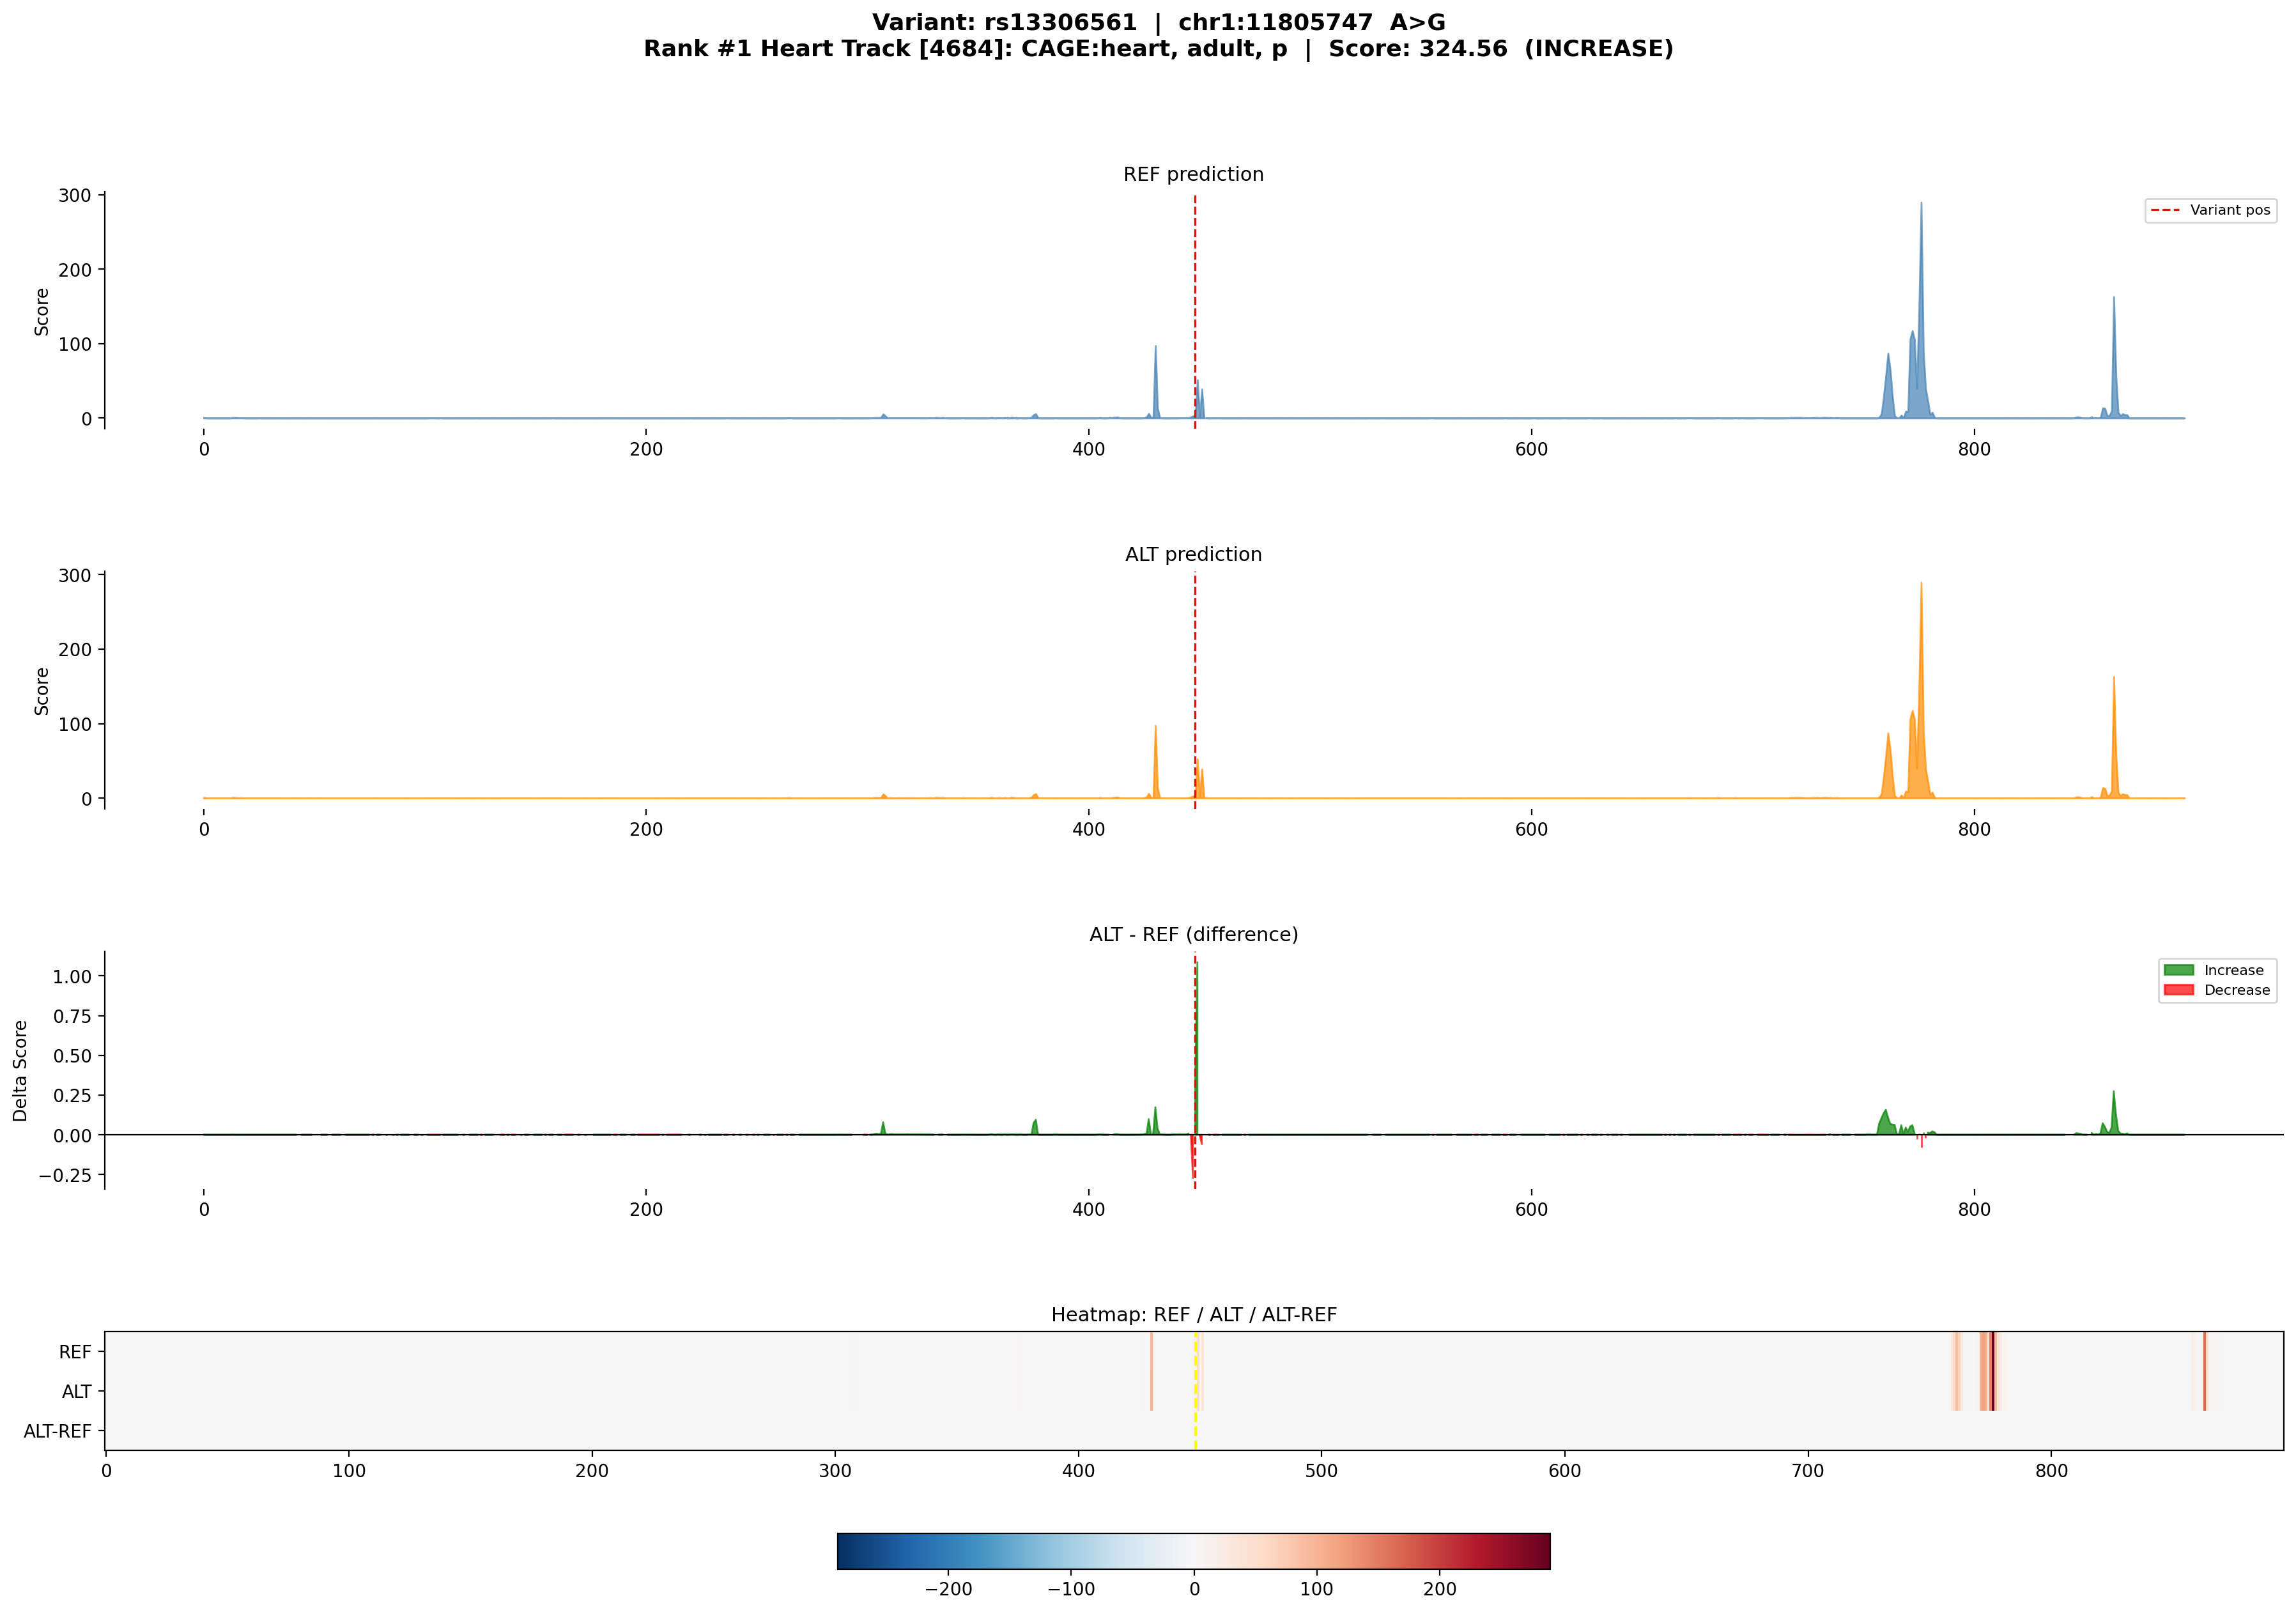

/tmp/ipykernel_10554/1864947087.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved → /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/rs17037388_rank2_CAGE_heart_adult_p.png


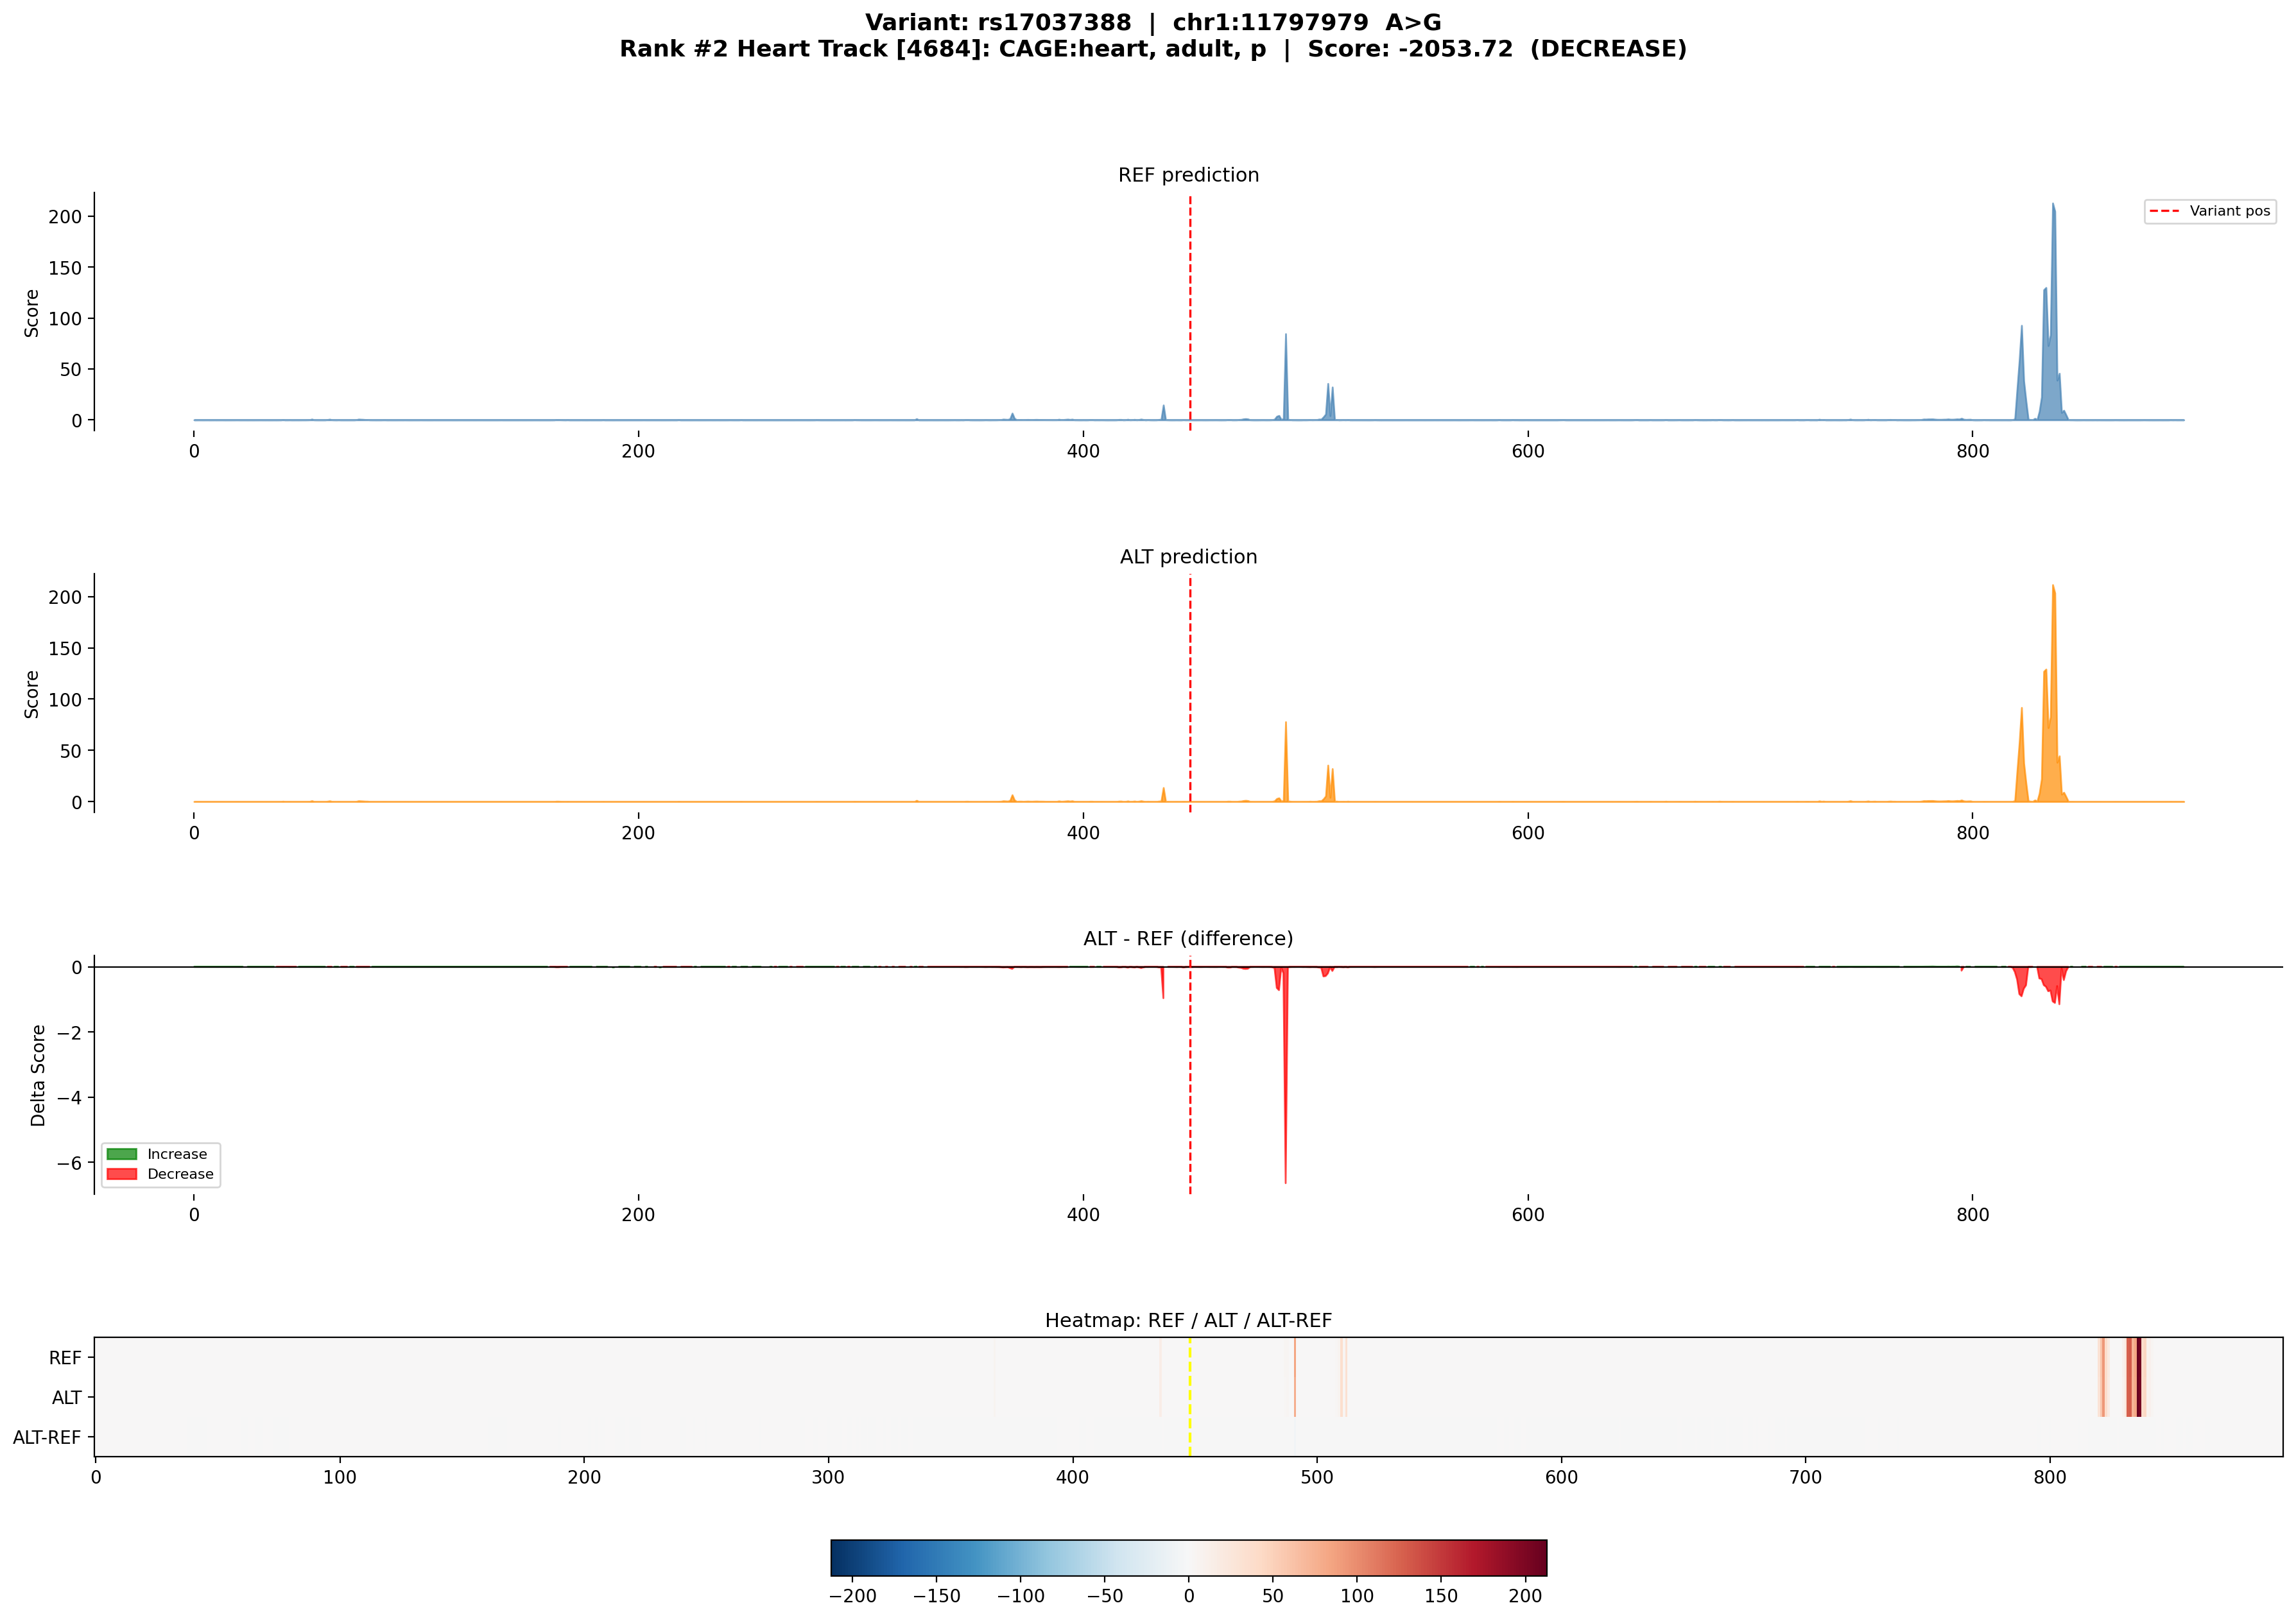

In [34]:
import matplotlib.gridspec as gridspec

# ============================================================
# THEN: Plot using df_heart
# ============================================================

plot_variant_heart_tracks_from_df(
    df_heart=df_heart,
    reference_predictions=reference_predictions,
    alternate_predictions=alternate_predictions,
    base_dir=BASE_DIR,
    top_n=1
)

In [35]:
df_heart['track_index'] = df_heart['track'].str.split('_').str[0].astype(int)
print(df_heart)

    variant_id chrom       pos ref alt  rank                      track  \
11  rs17037388  chr1  11797979   A   G     2  4684_CAGE:heart, adult, p   
12  rs17037388  chr1  11797979   A   G     3  4948_CAGE:heart, adult, d   
14  rs17037388  chr1  11797979   A   G     5  4714_CAGE:heart, fetal, p   
16  rs17037388  chr1  11797979   A   G     7  4947_CAGE:heart, adult, d   
20  rs13306561  chr1  11805747   A   G     1  4684_CAGE:heart, adult, p   
23  rs13306561  chr1  11805747   A   G     4  4714_CAGE:heart, fetal, p   
25  rs13306561  chr1  11805747   A   G     6  4948_CAGE:heart, adult, d   

          score    abs_score direction  track_index  
11 -2053.716797  2053.716797  DECREASE         4684  
12 -1366.216431  1366.216431  DECREASE         4948  
14 -1129.091553  1129.091553  DECREASE         4714  
16  -847.534607   847.534607  DECREASE         4947  
20   324.558014   324.558014  INCREASE         4684  
23   237.762955   237.762955  INCREASE         4714  
25   211.921127   211

/tmp/ipykernel_10554/2876899514.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_heart['track_index'] = df_heart['track'].str.split('_').str[0].astype(int)


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kipoiseq

def get_variant_predictions(variant_row, model, fasta_extractor, sequence_length=SEQUENCE_LENGTH):
    variant = kipoiseq.Variant(
        chrom=variant_row['chrom'],
        pos=int(variant_row['pos']),
        ref=variant_row['ref'],
        alt=variant_row['alt'],
        id=variant_row['variant_id']
    )

    interval = kipoiseq.Interval(
        variant.chrom,
        variant.start,
        variant.start
    ).resize(sequence_length)

    seq_extractor = kipoiseq.extractors.VariantSeqExtractor(
        reference_sequence=fasta_extractor
    )
    center = interval.center() - interval.start

    reference = seq_extractor.extract(interval, [], anchor=center)
    alternate = seq_extractor.extract(interval, [variant], anchor=center)

    reference_prediction = model.predict_on_batch(
        one_hot_encode(reference)[np.newaxis]
    )['human'][0]

    alternate_prediction = model.predict_on_batch(
        one_hot_encode(alternate)[np.newaxis]
    )['human'][0]

    plot_interval = interval.resize(reference_prediction.shape[0] * 128)

    return variant, plot_interval, reference_prediction, alternate_prediction


def plot_one_track_separately(plot_interval, reference_prediction, alternate_prediction,
                              track_idx, track_label, variant_id, figsize=(18, 5)):
    x = np.linspace(plot_interval.start, plot_interval.end, num=reference_prediction.shape[0])
    delta = alternate_prediction[:, track_idx] - reference_prediction[:, track_idx]

    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True)

    axes[0].fill_between(x, reference_prediction[:, track_idx])
    axes[0].set_title(f"{variant_id} | {track_label} | REF")
    sns.despine(ax=axes[0], top=True, right=True)

    axes[1].fill_between(x, delta)
    axes[1].axvline((plot_interval.start + plot_interval.end) / 2, linestyle='--')
    axes[1].set_title(f"{variant_id} | {track_label} | ALT - REF")
    axes[1].set_xlabel(str(plot_interval))
    sns.despine(ax=axes[1], top=True, right=True)

    plt.tight_layout()
    plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

def plot_all_selected_tracks_together(
    variant_id,
    sub,
    plot_interval,
    reference_prediction,
    alternate_prediction,
    save_dir=None,
    figsize_per_track=(18, 2.8)
):
    """
    Combine all selected tracks for one variant into one figure.

    Parameters
    ----------
    variant_id : str
        Variant ID
    sub : DataFrame
        Subset of df_heart (or df_top) for one variant
    plot_interval : Interval
        Plot interval returned by get_variant_predictions
    reference_prediction : np.ndarray
        REF predictions from Enformer
    alternate_prediction : np.ndarray
        ALT predictions from Enformer
    save_dir : str or None
        Directory to save figure
    figsize_per_track : tuple
        Width, height per track row
    """
    sub = sub.sort_values('rank').copy()
    n_tracks = len(sub)

    x = np.linspace(plot_interval.start, plot_interval.end, num=reference_prediction.shape[0])

    fig, axes = plt.subplots(
        n_tracks, 2,
        figsize=(figsize_per_track[0], figsize_per_track[1] * n_tracks),
        sharex=True
    )

    # If only one track, axes is 1D; convert to 2D
    if n_tracks == 1:
        axes = np.array([axes])

    center_x = (plot_interval.start + plot_interval.end) / 2

    for i, (_, r) in enumerate(sub.iterrows()):
        track_idx = int(r['track_index']) if 'track_index' in r else int(r['track'].split('_', 1)[0])
        track_label = r['track_label'] if 'track_label' in r else r['track'].split('_', 1)[1]

        ref_signal = reference_prediction[:, track_idx]
        delta_signal = alternate_prediction[:, track_idx] - reference_prediction[:, track_idx]

        ax_ref = axes[i, 0]
        ax_delta = axes[i, 1]

        ax_ref.fill_between(x, ref_signal)
        ax_ref.axvline(center_x, linestyle='--', linewidth=1)
        ax_ref.set_title(
            f"{variant_id} | rank {r['rank']} | {track_label} | REF",
            fontsize=10
        )
        sns.despine(ax=ax_ref, top=True, right=True)

        ax_delta.fill_between(x, delta_signal)
        ax_delta.axvline(center_x, linestyle='--', linewidth=1)
        ax_delta.set_title(
            f"{variant_id} | rank {r['rank']} | {track_label} | ALT-REF | score={r['score']:.2f} | {r['direction']}",
            fontsize=10
        )
        sns.despine(ax=ax_delta, top=True, right=True)

    axes[-1, 0].set_xlabel(str(plot_interval))
    axes[-1, 1].set_xlabel(str(plot_interval))

    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        safe_variant = re.sub(r'[^A-Za-z0-9._-]+', '_', variant_id)
        out_png = os.path.join(save_dir, f"{safe_variant}__all_heart_tracks.png")
        fig.savefig(out_png, dpi=200, bbox_inches='tight')
        print(f"Saved: {out_png}")

    plt.show()
    plt.close(fig)

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

def plot_all_selected_tracks_together(
    variant_id,
    sub,
    plot_interval,
    reference_prediction,
    alternate_prediction,
    save_dir=None,
    figsize_per_track=(18, 2.8),
    ref_color='steelblue',
    diff_color='firebrick'
):
    sub = sub.sort_values('rank').copy()
    n_tracks = len(sub)

    x = np.linspace(plot_interval.start, plot_interval.end, num=reference_prediction.shape[0])

    fig, axes = plt.subplots(
        n_tracks, 2,
        figsize=(figsize_per_track[0], figsize_per_track[1] * n_tracks),
        sharex=True
    )

    if n_tracks == 1:
        axes = np.array([axes])

    center_x = (plot_interval.start + plot_interval.end) / 2

    for i, (_, r) in enumerate(sub.iterrows()):
        track_idx = int(r['track_index']) if 'track_index' in r else int(r['track'].split('_', 1)[0])
        track_label = r['track_label'] if 'track_label' in r else r['track'].split('_', 1)[1]

        ref_signal = reference_prediction[:, track_idx]
        delta_signal = alternate_prediction[:, track_idx] - reference_prediction[:, track_idx]

        ax_ref = axes[i, 0]
        ax_delta = axes[i, 1]

        ax_ref.fill_between(x, ref_signal, color=ref_color, alpha=0.85)
        ax_ref.axvline(center_x, linestyle='--', linewidth=1, color='black')
        ax_ref.set_title(
            f"{variant_id} | rank {r['rank']} | {track_label} | REF",
            fontsize=10
        )
        sns.despine(ax=ax_ref, top=True, right=True)

        ax_delta.fill_between(x, delta_signal, color=diff_color, alpha=0.85)
        ax_delta.axhline(0, linestyle='-', linewidth=0.8, color='black')
        ax_delta.axvline(center_x, linestyle='--', linewidth=1, color='black')
        ax_delta.set_title(
            f"{variant_id} | rank {r['rank']} | {track_label} | ALT-REF | score={r['score']:.2f} | {r['direction']}",
            fontsize=10
        )
        sns.despine(ax=ax_delta, top=True, right=True)

    axes[-1, 0].set_xlabel(str(plot_interval))
    axes[-1, 1].set_xlabel(str(plot_interval))

    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        safe_variant = re.sub(r'[^A-Za-z0-9._-]+', '_', variant_id)
        out_png = os.path.join(save_dir, f"{safe_variant}__top_heart_track.png")
        fig.savefig(out_png, dpi=200, bbox_inches='tight')
        print(f"Saved: {out_png}")

    plt.show()
    plt.close(fig)

Saved: /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/heart_track_top1_plots/rs17037388__top_heart_track.png


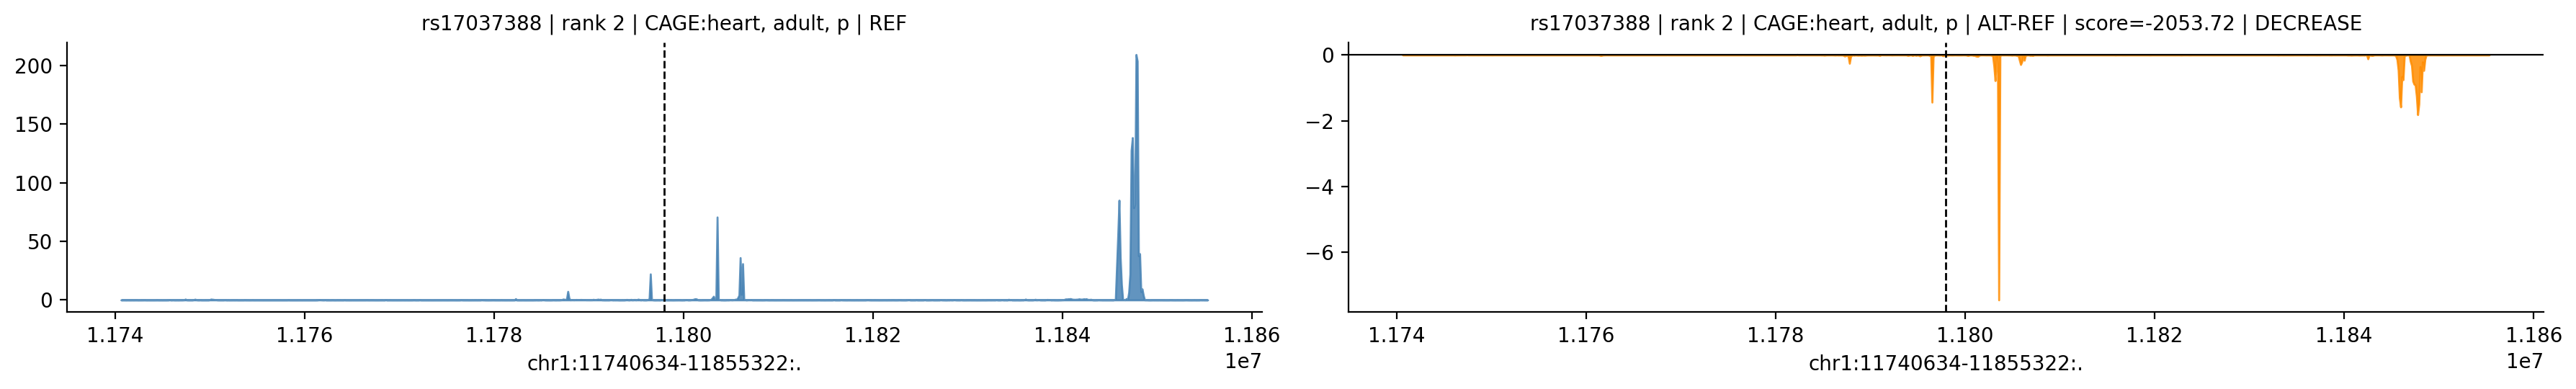

Saved: /content/drive/MyDrive/Enformer_tutorial_Google_DeepMind//gwas.amgen/heart_track_top1_plots/rs13306561__top_heart_track.png


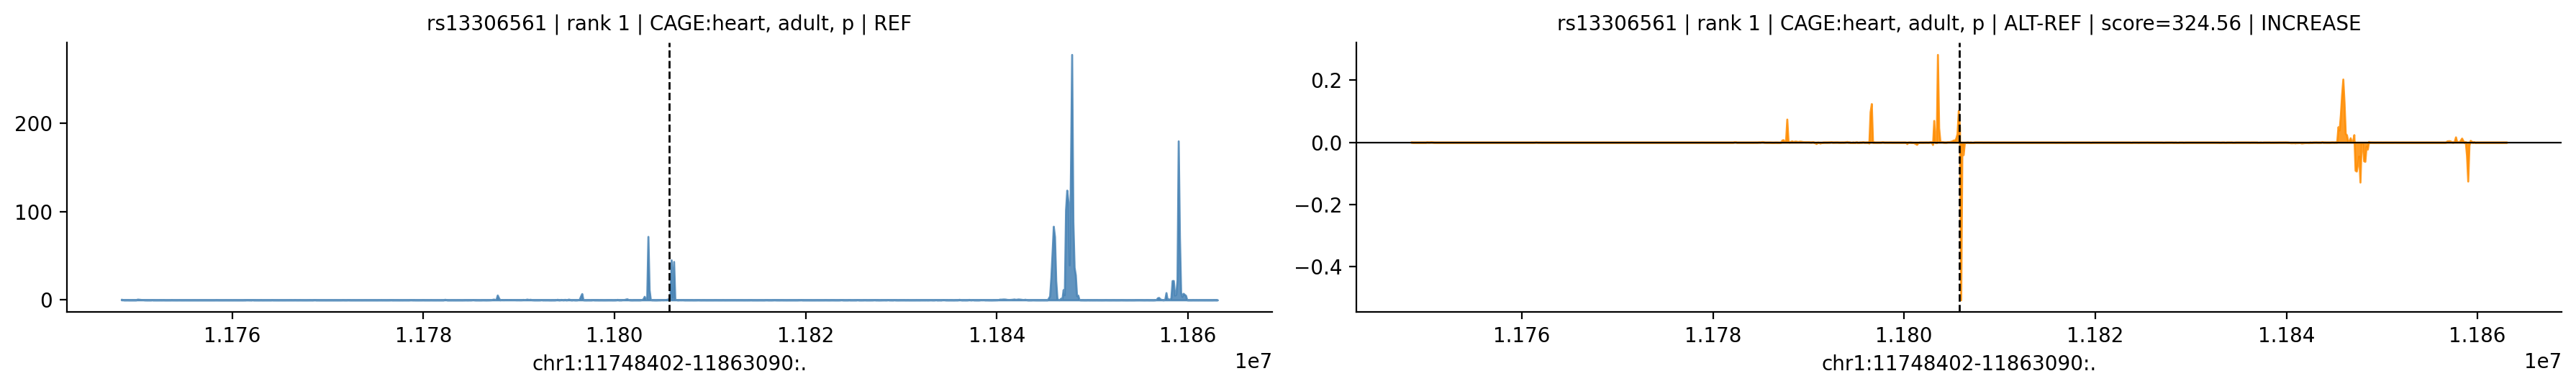

In [39]:
df_heart = df_heart.copy()
df_heart['track_index'] = df_heart['track'].str.split('_', n=1).str[0].astype(int)
df_heart['track_label'] = df_heart['track'].str.split('_', n=1).str[1]

save_dir = f"{BASE_DIR}/gwas.amgen/heart_track_top1_plots"

for variant_id, sub in df_heart.groupby('variant_id', sort=False):

    sub = sub.sort_values('rank').head(1)

    row = sub.iloc[0]

    variant, plot_interval, reference_prediction, alternate_prediction = get_variant_predictions(
        variant_row=row,
        model=model,
        fasta_extractor=fasta_extractor,
        sequence_length=SEQUENCE_LENGTH
    )

    plot_all_selected_tracks_together(
        variant_id=variant_id,
        sub=sub,
        plot_interval=plot_interval,
        reference_prediction=reference_prediction,
        alternate_prediction=alternate_prediction,
        save_dir=save_dir,
        ref_color='steelblue',
        diff_color='darkorange'
    )